In [70]:
import numpy as np
import pandas as pd
import scanpy as sc
import infercnvpy as cnv
import matplotlib.pyplot as plt
import warnings

import matplotlib.pyplot as plt
import matplotlib as mpl

import matplotlib as mpl
import seaborn as sns

warnings.simplefilter("ignore")

mpl.rcParams['figure.dpi'] = 300
mpl.rcParams['pdf.fonttype'] = 42
sc.settings.set_figure_params(facecolor=(0, 0, 0, 0), dpi=50, dpi_save=600)

sns.set_style({'axes.grid': False})



In [2]:
genecode = pd.read_csv("/home/xuquan/projects/pdac/revision/data/hg38_gencode_v27.txt", sep='\t', header=None, index_col=0)

In [3]:
project_dir = '/home/xuquan/projects/pdac'
sc.settings.figdir = f'{project_dir}/figures/'
fig_dir = f'{project_dir}/figures/'

plate_level_all0 = pd.read_csv(f"{project_dir}/db/pdac_color.txt",
                               sep='\t', header=None, index_col=0)
plate_level_all = plate_level_all0.to_dict()[1]
plate_level_all['nan'] = 'lightgray'


### All

In [19]:

adata = sc.read_h5ad("/home/xuquan/projects/pdac/pdac_atlas/all/pdac_atlas.h5ad")

adata.var = pd.merge(adata.var, genecode, left_index=True, right_index=True, how='left')
adata.var.columns=["chromosome", "start", "end"]


In [20]:
# We provide all immune cell types as "normal cells".
cnv.tl.infercnv(
    adata,
    reference_key="level_1",
    reference_cat=['Lymphoid','Erythrocyte'],
    chunksize=1000,
    n_jobs=100,
    window_size=250,
)


100%|██████████| 674/674 [05:59<00:00,  1.88it/s]


In [21]:
cnv.tl.pca(adata)
cnv.pp.neighbors(adata, use_rep="cnv_pca")
cnv.tl.leiden(adata)


In [22]:
cnv.tl.cnv_score(adata, groupby='cnv_leiden')


In [31]:
sc.pl.umap(adata, color="cnv_score", show=False, 
            wspace=.1, size=2, ncols=1, frameon=False, vmin=0, vmax=0.017,
            save='all_cnv_score.pdf')


<Axes: title={'center': 'cnv_score'}, xlabel='UMAP1', ylabel='UMAP2'>

In [5]:
adata_obs = pd.read_csv('../revision/scripts/t.txt')

ct_order = ['epithelial', 'mesenchyme', 'endocine', 'endothelial', 
         'myeloid', 'lymphoid','erythrocyte', 'mast', 'schwann']

ct_order = [w.capitalize() for w in ct_order]


In [17]:
# adata_obs

<Axes: xlabel='level_1', ylabel='cnv_score'>

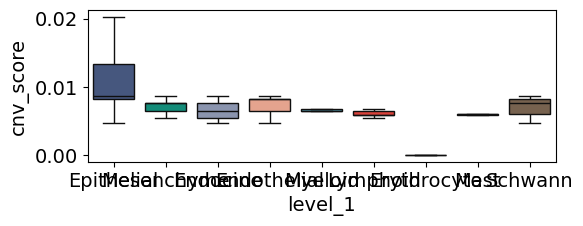

In [6]:
fig, ax = plt.subplots(figsize=(6, 2))

sns.boxplot(adata_obs, x='level_1',y='cnv_score', palette=plate_level_all, showfliers=False, order=ct_order)
# plt.xticks(rotation=30)

# plt.savefig(f"{fig_dir}/all_cnv_score.pdf", bbox_inches='tight')


In [13]:
import scipy.stats as stats
group_epi = adata_obs[adata_obs.level_1=='Epithelial'].cnv_score
group_other = adata_obs[adata_obs.level_1!='Epithelial'].cnv_score

res_greater = stats.mannwhitneyu(group_other, group_epi, alternative='less', nan_policy='omit')
print(f"Greater p-value:", res_greater.pvalue)



Greater p-value: 0.0


In [14]:
res_greater

MannwhitneyuResult(statistic=np.float64(15111701172.5), pvalue=np.float64(0.0))

In [86]:
from scipy import stats

for i in adata.obs.level_1.unique():
    stat, p_value = stats.mannwhitneyu(adata[adata.obs.level_1.isin([i])].obs.cnv_score.tolist(), 
                                       adata[adata.obs.level_1.isin(['Lymphoid','Erythrocyte'])].obs.cnv_score.tolist(), 
                                       alternative="greater")

    print(f"{i} P-value: {p_value}")

Epithelial P-value: 0.0
Mesenchyme P-value: 0.0
Myeloid P-value: 0.0
Lymphoid P-value: 0.3994058132654763
Mast P-value: 0.9999999742102766
Endothelial P-value: 0.0
Schwann P-value: 0.0
Endocine P-value: 9.497874308402939e-137
Erythrocyte P-value: 1.0


In [ ]:
cnv.pl.chromosome_heatmap(adata, groupby="level_1")


### Cancer

In [15]:
adata_epi = sc.read_h5ad("/home/xuquan/projects/pdac/pdac_atlas/epithelial/pdac_atlas_epi.h5ad")
adata_epi.var = pd.merge(adata_epi.var, genecode, left_index=True, right_index=True, how='left')
adata_epi.var.columns=["chromosome", "start", "end"]


In [16]:
cnv.tl.infercnv(
    adata_epi,
    reference_key="level_2",
    reference_cat=['Acinar(CTRB2)','Ductal(AQP1)'],
#     reference_cat=None,
    window_size=250,
)

100%|██████████| 39/39 [02:15<00:00,  3.48s/it] 


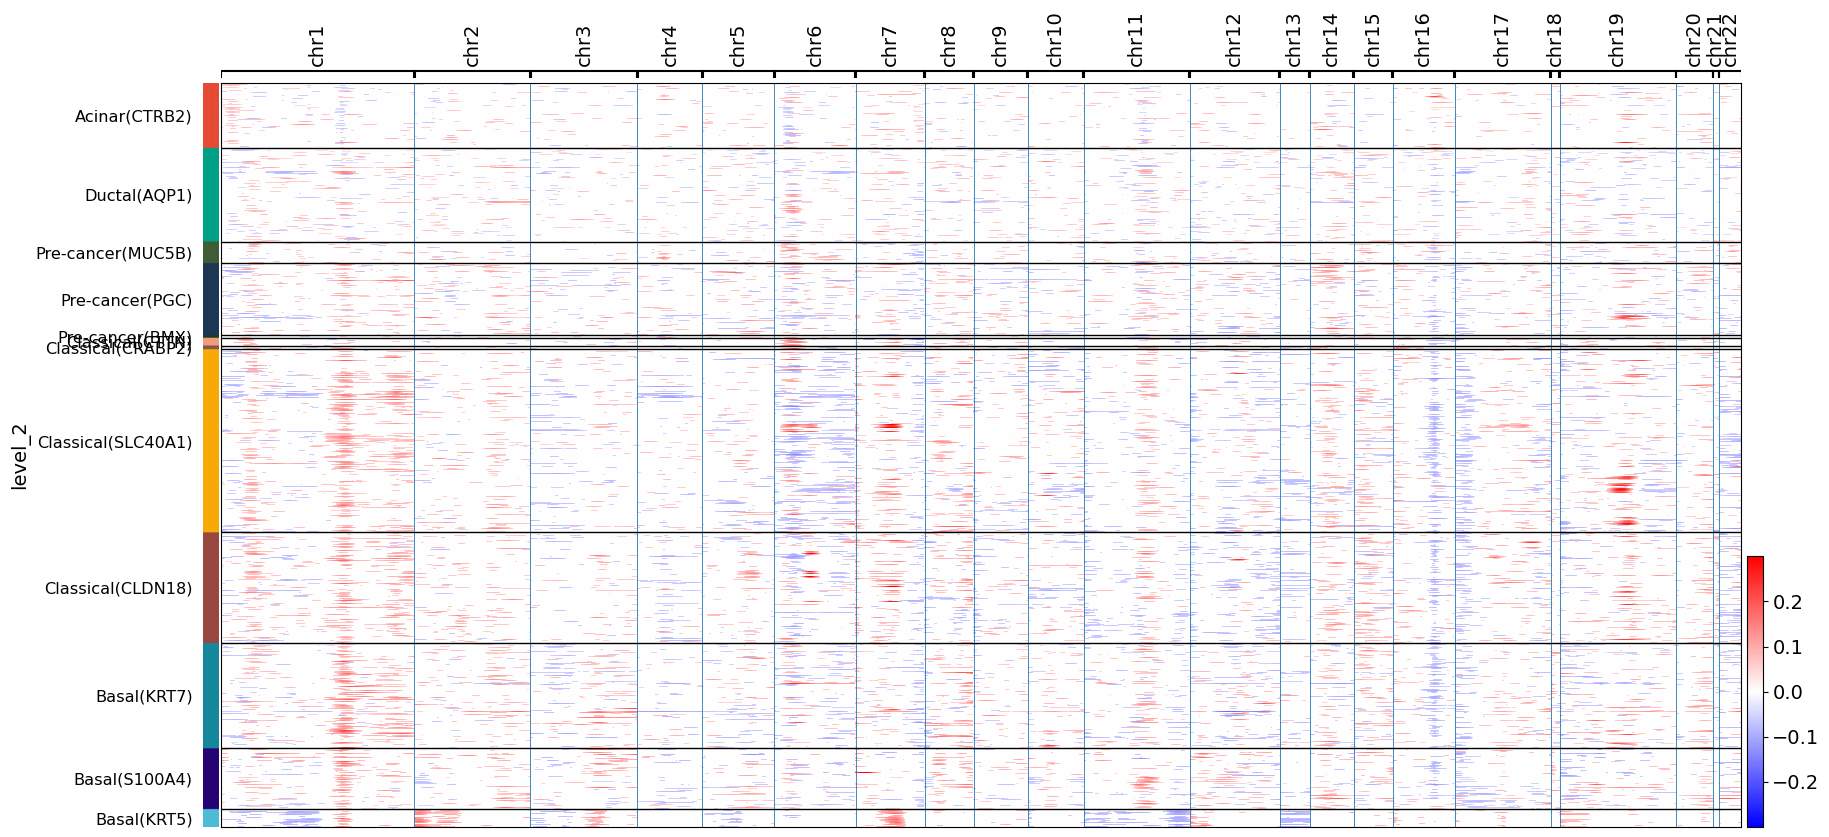

In [20]:
cnv.pl.chromosome_heatmap(adata_epi, groupby="level_2", vmin=-0.3,vmax=0.3, 
                          figsize=(20,10), save='epi_cnv_heatmap.pdf')


In [17]:
cnv.tl.pca(adata_epi)
cnv.pp.neighbors(adata_epi, use_rep="cnv_pca")
cnv.tl.leiden(adata_epi)


In [14]:
# adata_epi.obs

In [19]:
cnv.tl.cnv_score(adata_epi, groupby='cnv_leiden')

# sc.pl.umap(adata_epi, color="cnv_score", show=False, 
#             wspace=.1, size=2, ncols=1, frameon=False, vmin=0,
#             save='epi_cnv_score.pdf')


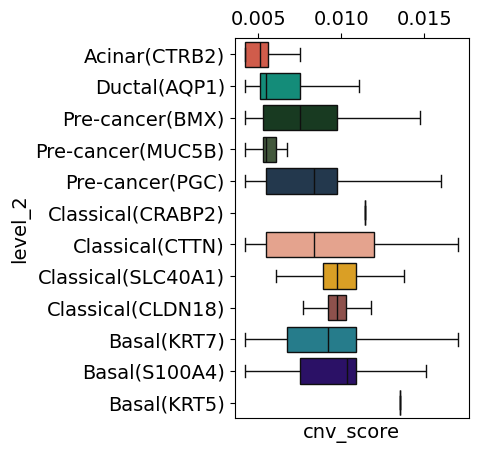

In [20]:
fig, ax = plt.subplots(figsize=(3, 5))

ct_order = ['Acinar(CTRB2)', 'Ductal(AQP1)', 'Pre-cancer(BMX)', 'Pre-cancer(MUC5B)', 
             'Pre-cancer(PGC)', 'Classical(CRABP2)', 'Classical(CTTN)','Classical(SLC40A1)',
             'Classical(CLDN18)', 'Basal(KRT7)', 'Basal(S100A4)', 'Basal(KRT5)']
ax = sns.boxplot(adata_epi.obs, y='level_2',x='cnv_score', palette=plate_level_all, 
                 order=ct_order, showfliers=False)
ax.tick_params(top=True, labeltop=True, bottom=False, labelbottom=False)
# ax.set_xlim(left=0, right=0.025) 

# plt.savefig(f"{fig_dir}/epi_cnv_score.pdf", bbox_inches='tight')


In [59]:
adata_epi.obs[['level_1','cnv_score']].groupby('level_1').mean()

,cnv_score
level_1,
Acinar,0.005563
Basal,0.009863
Classical,0.009839
Ductal,0.006660
Pre-cancer,0.007495


In [21]:
from scipy import stats

for i in adata_epi.obs.level_2.unique():
    stat, p_value = stats.mannwhitneyu(adata_epi[adata_epi.obs.level_2.isin([i])].obs.cnv_score.tolist(), 
                                       adata_epi[adata_epi.obs.level_2.isin(['Aconar(CTRB2)','Ductal(AQP1)'])].obs.cnv_score.tolist(), 
                                       alternative="greater")

    print(f"{i} P-value: {p_value}")

Basal(KRT7) P-value: 0.0
Basal(S100A4) P-value: 0.0
Classical(SLC40A1) P-value: 0.0
Pre-cancer(PGC) P-value: 0.0
Ductal(AQP1) P-value: 0.5000001292555566
Pre-cancer(MUC5B) P-value: 0.9999999999999928
Classical(CLDN18) P-value: 0.0
Acinar(CTRB2) P-value: 1.0
Classical(CTTN) P-value: 1.575076241665146e-197
Pre-cancer(BMX) P-value: 1.376843584011756e-40
Basal(KRT5) P-value: 0.0
Classical(CRABP2) P-value: 0.0


In [22]:
stat, p_value = stats.mannwhitneyu(adata_epi[adata_epi.obs.level_2.isin(['Basal(KRT7)',
                                                                         'Basal(S100A4)',
                                                                        'Basal(KRT5)'])].obs.cnv_score.tolist(), 
                                   adata_epi[adata_epi.obs.level_2.isin(['Classical(SLC40A1)',
                                                                         'Classical(CLDN18)',
                                                                        'Classical(CTTN)',
                                                                        'Classical(CRABP2)'])].obs.cnv_score.tolist(), 
                                   alternative="greater")
print(f"P-value: {p_value}")

P-value: 0.0003063628946537588


In [55]:
# adata_epi.obs

In [102]:
p_res = {}
for i in adata_epi.obs.level_2.unique():
    p_res[i]=[]
    for j in adata_epi.obs.level_2.unique():
        stat, p_value = stats.mannwhitneyu(adata_epi[adata_epi.obs.level_2.isin([i])].obs.cnv_score.tolist(), 
                                           adata_epi[adata_epi.obs.level_2.isin([j])].obs.cnv_score.tolist(), 
                                       alternative="greater")
        p_res[i].append(float(p_value))

p_res = pd.DataFrame(p_res)
p_res.index = adata_epi.obs.level_2.unique()
p_res = -np.log10(p_res)
p_res = np.clip(p_res, a_min=None, a_max=2)
p_res = p_res[ct_order].loc[ct_order]

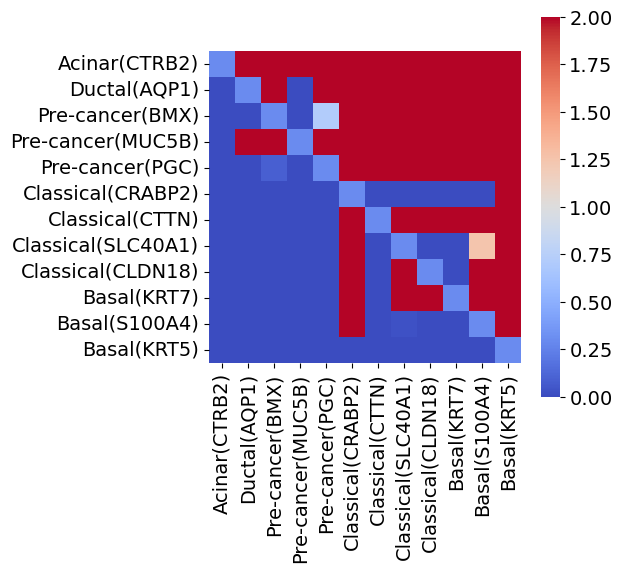

In [104]:
fig, ax = plt.subplots(figsize=(5, 5))
ax=sns.heatmap(p_res, square=True, cmap='coolwarm')
plt.savefig(f"{fig_dir}/epi_cnv_score_p_heatmap.pdf", bbox_inches='tight')


In [92]:
center=-np.log10(0.05), vmin=0, vmax=2, 

np.float64(1.3010299956639813)

### CAF

In [49]:
adata_mes = sc.read_h5ad("/home/xuquan/projects/pdac/pdac_atlas/epithelial/pdac_atlas_mes.h5ad")
adata_mes.var = pd.merge(adata_mes.var, genecode, left_index=True, right_index=True, how='left')
adata_mes.var.columns=["chromosome", "start", "end"]


In [50]:
cnv.tl.infercnv(
    adata_mes,
    reference_key="level_2",
    reference_cat=None,
    window_size=250,
)

100%|██████████| 23/23 [00:38<00:00,  1.67s/it]


In [90]:
cnv.tl.pca(adata_mes)
cnv.pp.neighbors(adata_mes, use_rep="cnv_pca")
cnv.tl.leiden(adata_mes)


In [91]:
cnv.tl.cnv_score(adata_mes, groupby='cnv_leiden')

sc.pl.umap(adata_mes, color="cnv_score", show=False, 
            wspace=.1, size=2, ncols=1, frameon=False, vmin=0,
            save='mes_cnv_score.pdf')


<Axes: title={'center': 'cnv_score'}, xlabel='UMAP1', ylabel='UMAP2'>

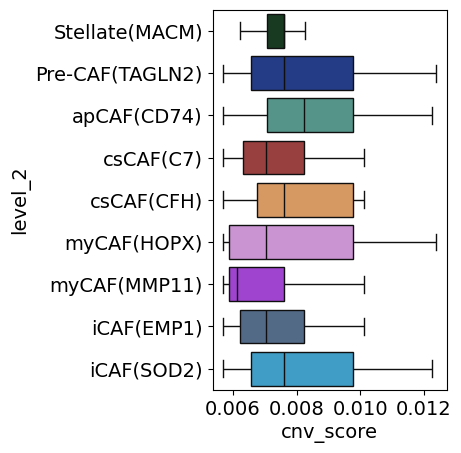

In [103]:
fig, ax = plt.subplots(figsize=(3, 5))

sns.boxplot(adata_mes.obs, y='level_2',x='cnv_score', palette=plate_level_all,
           order=['Stellate(MACM)', 'Pre-CAF(TAGLN2)', 'apCAF(CD74)', 'csCAF(C7)', 'csCAF(CFH)', 'myCAF(HOPX)', 'myCAF(MMP11)', 'iCAF(EMP1)', 'iCAF(SOD2)'],
           showfliers=False)


plt.savefig(f"{fig_dir}/mes_cnv_score.pdf", bbox_inches='tight')


In [93]:
from scipy import stats

for i in adata_mes.obs.level_2.unique():
    stat, p_value = stats.mannwhitneyu(adata_mes[adata_mes.obs.level_2.isin([i])].obs.cnv_score.tolist(), 
                                       adata_mes[adata_mes.obs.level_2.isin(['Stellate(MACM)'])].obs.cnv_score.tolist(), 
                                       alternative="greater")

    print(f"{i} P-value: {p_value}")

Pre-CAF(TAGLN2) P-value: 0.9999998956680562
Stellate(MACM) P-value: 0.500000142252409
myCAF(MMP11) P-value: 1.0
myCAF(HOPX) P-value: 1.0
iCAF(EMP1) P-value: 1.0
apCAF(CD74) P-value: 3.3124721353356447e-128
csCAF(C7) P-value: 1.0
iCAF(SOD2) P-value: 0.9999999999989417
csCAF(CFH) P-value: 0.7645798488437474
